# Task: Tourist Recommendation System for Baltistan
**Algorithms:** (1) Rating filtering (weighted rating), (2) Content-based filtering (TF-IDF + cosine similarity), (3) Hybrid of both.

**Dataset:** `baltistan_places.csv` (27 real places) and `baltistan_ratings_SYNTHETIC.csv` (simulated ratings, replace with real survey data when available).

**Task steps**
1. Load and explore the data.
2. Build the rating-filtering recommender.
3. Build the content-based recommender.
4. Combine both into a hybrid recommender.
5. Evaluate all three and compare.

## Step 1: Load the data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

places  = pd.read_csv('baltistan_places.csv')
ratings = pd.read_csv('baltistan_ratings_SYNTHETIC.csv')
users   = pd.read_csv('baltistan_users_SYNTHETIC.csv')

print(places.shape, ratings.shape, users.shape)
places.head()

(27, 15) (2815, 6) (200, 4)


,place_id,name,district,category,interest_tags,activities,best_season,difficulty,altitude_m,latitude,longitude,access,description,avg_rating_synthetic,rating_count_synthetic
0,P001,Shangrila Resort & Lower Kachura Lake,Skardu,Lake,nature;photography;family,boating;photography;picnic;sightseeing,May-Oct,Easy,2350,35.33,75.43,Road,Famous lakeside resort area with a clear blue ...,4.28,105
1,P002,Upper Kachura Lake,Skardu,Lake,nature;photography;camping,walking;photography;camping;boating,May-Oct,Easy,2500,35.36,75.46,Road + short walk,Quiet alpine lake above Lower Kachura with cal...,4.06,112
2,P003,Satpara Lake,Skardu,Lake,nature;family;photography,boating;sightseeing;photography,Apr-Oct,Easy,2636,35.22,75.69,Road,Large lake near Skardu that supplies the city ...,4.08,113
3,P004,Deosai National Park,Skardu,National Park / Plateau,nature;adventure;camping;photography,camping;wildlife;stargazing;jeep safari;photog...,Jun-Sep,Moderate,4114,35.03,75.42,Jeep track,"High-altitude plateau known for wildflowers, H...",4.54,130
4,P005,Sheosar Lake,Skardu,Lake,nature;camping;photography,camping;photography;stargazing,Jun-Sep,Moderate,4142,34.93,75.35,Jeep track,Large high-altitude lake inside Deosai plains ...,4.45,110


rating
2      52
3     611
4    1437
5     715
Name: count, dtype: int64

district
Skardu      10
Shigar       7
Ghanche      7
Kharmang     2
Rondu        1
Name: count, dtype: int64


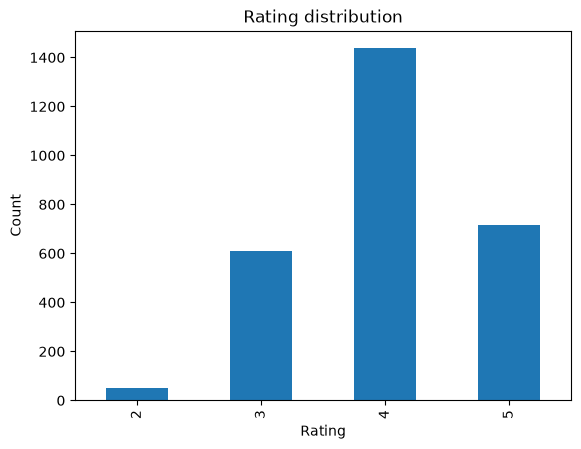

In [2]:
# Quick exploration
print(ratings.rating.value_counts().sort_index())
print()
print(places.district.value_counts())

ratings.rating.value_counts().sort_index().plot(kind='bar', title='Rating distribution')
plt.xlabel('Rating'); plt.ylabel('Count'); plt.show()

## Step 2: Rating filtering (weighted rating)
A place with 2 ratings of 5 stars should not beat a place with 100 ratings averaging 4.5. So we use a weighted rating:

**WR = (v / (v + m)) * R + (m / (v + m)) * C**

- R = average rating of the place, v = number of ratings of the place
- m = minimum ratings needed (we use the 60th percentile of rating counts)
- C = mean rating of all ratings

In [3]:
stats = ratings.groupby('place_id').rating.agg(R='mean', v='count').reset_index()
C_mean = ratings.rating.mean()
m = stats.v.quantile(0.60)

stats['WR'] = (stats.v/(stats.v+m))*stats.R + (m/(stats.v+m))*C_mean
rating_table = places.merge(stats, on='place_id').sort_values('WR', ascending=False)

print('C (global mean) =', round(C_mean,3), '| m =', round(m,1))
rating_table[['name','district','category','R','v','WR']].head(10).round(2)

C (global mean) = 4.0 | m = 108.6


,name,district,category,R,v,WR
3,Deosai National Park,Skardu,National Park / Plateau,4.54,130,4.29
11,Khaplu Palace (Khaplu Fort),Ghanche,Fort / Heritage,4.47,107,4.23
16,K2 Base Camp / Baltoro Glacier Trek,Shigar,Trekking / Mountain,4.48,101,4.23
4,Sheosar Lake,Skardu,Lake,4.45,110,4.22
13,Khaplu Valley,Ghanche,Valley,4.37,115,4.19
14,Hushe Valley,Ghanche,Valley / Trek base,4.35,123,4.19
9,Shigar Fort (Fong Khar),Shigar,Fort / Heritage,4.29,112,4.15
0,Shangrila Resort & Lower Kachura Lake,Skardu,Lake,4.28,105,4.14
10,Shigar Valley,Shigar,Valley,4.20,108,4.10
8,Basho Valley,Skardu,Valley,4.18,114,4.09


In [4]:
def recommend_by_rating(n=5, district=None, category=None, min_rating=3.5, exclude=None):
    df = rating_table[rating_table.R >= min_rating]
    if district: df = df[df.district.str.lower() == district.lower()]
    if category: df = df[df.category.str.contains(category, case=False)]
    if exclude:  df = df[~df.place_id.isin(exclude)]
    return df[['place_id','name','district','category','R','v','WR']].head(n).round(2)

print('Top 5 overall');         display(recommend_by_rating(5))
print('Top 3 in Ghanche');      display(recommend_by_rating(3, district='Ghanche'))
print('Top 3 lakes');           display(recommend_by_rating(3, category='Lake'))

Top 5 overall


,place_id,name,district,category,R,v,WR
3,P004,Deosai National Park,Skardu,National Park / Plateau,4.54,130,4.29
11,P012,Khaplu Palace (Khaplu Fort),Ghanche,Fort / Heritage,4.47,107,4.23
16,P017,K2 Base Camp / Baltoro Glacier Trek,Shigar,Trekking / Mountain,4.48,101,4.23
4,P005,Sheosar Lake,Skardu,Lake,4.45,110,4.22
13,P014,Khaplu Valley,Ghanche,Valley,4.37,115,4.19


Top 3 in Ghanche


,place_id,name,district,category,R,v,WR
11,P012,Khaplu Palace (Khaplu Fort),Ghanche,Fort / Heritage,4.47,107,4.23
13,P014,Khaplu Valley,Ghanche,Valley,4.37,115,4.19
14,P015,Hushe Valley,Ghanche,Valley / Trek base,4.35,123,4.19


Top 3 lakes


,place_id,name,district,category,R,v,WR
4,P005,Sheosar Lake,Skardu,Lake,4.45,110,4.22
0,P001,Shangrila Resort & Lower Kachura Lake,Skardu,Lake,4.28,105,4.14
2,P003,Satpara Lake,Skardu,Lake,4.08,113,4.04


## Step 3: Content-based filtering
Each place is described as text (category, tags, activities, season, difficulty, district, description). TF-IDF converts it to numbers, and cosine similarity measures how close a place is to the tourist's interests.

In [5]:
def make_text(r):
    # repeat interest tags and activities so they carry more weight than the long description
    return ' '.join([
        r.category, r.district, r.difficulty, r.best_season,
        (r.interest_tags.replace(';',' ') + ' ') * 3,
        (r.activities.replace(';',' ') + ' ') * 2,
        r.description])

places['text'] = places.apply(make_text, axis=1)
tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1,2))
X = tfidf.fit_transform(places.text)
print('TF-IDF matrix:', X.shape)

TF-IDF matrix: (27, 523)


In [6]:
def recommend_by_content(interests, n=5, exclude=None):
    """interests: text such as 'trekking camping glacier adventure'"""
    q = tfidf.transform([interests])
    sim = cosine_similarity(q, X).ravel()
    out = places[['place_id','name','district','category']].copy()
    out['content_score'] = sim
    if exclude: out = out[~out.place_id.isin(exclude)]
    return out.sort_values('content_score', ascending=False).head(n).round(3)

print('Adventure tourist');    display(recommend_by_content('adventure trekking camping glacier'))
print('Culture + photography');display(recommend_by_content('culture heritage fort history photography'))
print('Family, relaxed');      display(recommend_by_content('family lake easy picnic boating'))

Adventure tourist


,place_id,name,district,category,content_score
19,P020,Chogo Lungma Glacier / Arandu Trek,Shigar,Trekking / Glacier,0.640
18,P019,Biafo Glacier Trek,Shigar,Trekking / Glacier,0.637
16,P017,K2 Base Camp / Baltoro Glacier Trek,Shigar,Trekking / Mountain,0.455
15,P016,Masherbrum Base Camp Trek,Ghanche,Trekking / Mountain,0.373
14,P015,Hushe Valley,Ghanche,Valley / Trek base,0.343


Culture + photography


,place_id,name,district,category,content_score
9,P010,Shigar Fort (Fong Khar),Shigar,Fort / Heritage,0.531
11,P012,Khaplu Palace (Khaplu Fort),Ghanche,Fort / Heritage,0.486
5,P006,Kharpocho (Skardu) Fort,Skardu,Fort / Heritage,0.377
21,P022,Buddha Rock (Manthal),Skardu,Buddhist Heritage,0.255
12,P013,Chaqchan Mosque,Ghanche,Religious / Heritage,0.228


Family, relaxed


,place_id,name,district,category,content_score
0,P001,Shangrila Resort & Lower Kachura Lake,Skardu,Lake,0.414
2,P003,Satpara Lake,Skardu,Lake,0.301
7,P008,Manthokha Waterfall,Kharmang,Waterfall,0.237
1,P002,Upper Kachura Lake,Skardu,Lake,0.197
25,P026,Shyok River Viewpoints (Khaplu side),Ghanche,River / Viewpoint,0.160


In [7]:
def similar_places(place_name, n=5):
    i = places.index[places.name.str.contains(place_name, case=False)][0]
    sim = cosine_similarity(X[i], X).ravel()
    out = places[['name','district','category']].copy()
    out['similarity'] = sim
    return out.drop(index=i).sort_values('similarity', ascending=False).head(n).round(3)

print('Places similar to Shangrila');  display(similar_places('Shangrila'))

Places similar to Shangrila


,name,district,category,similarity
7,Manthokha Waterfall,Kharmang,Waterfall,0.496
13,Khaplu Valley,Ghanche,Valley,0.296
25,Shyok River Viewpoints (Khaplu side),Ghanche,River / Viewpoint,0.253
2,Satpara Lake,Skardu,Lake,0.247
1,Upper Kachura Lake,Skardu,Lake,0.231


## Step 4: Hybrid recommender
Both scores are scaled to 0-1 and combined:

**Final Score = alpha * Content Score + (1 - alpha) * Weighted Rating Score**

In [8]:
def minmax(s):
    return (s - s.min()) / (s.max() - s.min() + 1e-9)

def recommend_hybrid(interests, n=5, alpha=0.6, exclude=None, district=None, season=None):
    q = tfidf.transform([interests])
    c = pd.Series(cosine_similarity(q, X).ravel(), index=places.place_id)
    w = rating_table.set_index('place_id').WR.reindex(places.place_id)
    df = places[['place_id','name','district','category','best_season']].copy()
    df['content'] = minmax(c).values
    df['rating']  = minmax(w).values
    df['final_score'] = alpha*df.content + (1-alpha)*df.rating
    if exclude:  df = df[~df.place_id.isin(exclude)]
    if district: df = df[df.district.str.lower() == district.lower()]
    if season:   df = df[df.best_season.str.contains(season, case=False)]
    return df.sort_values('final_score', ascending=False).head(n).round(3)

print('Hybrid: adventure tourist');  display(recommend_hybrid('adventure trekking camping glacier'))
print('Hybrid: culture tourist, Ghanche only'); display(recommend_hybrid('culture heritage history photography', district='Ghanche', n=3))

Hybrid: adventure tourist


,place_id,name,district,category,best_season,content,rating,final_score
18,P019,Biafo Glacier Trek,Shigar,Trekking / Glacier,Jun-Aug,0.995,0.605,0.839
16,P017,K2 Base Camp / Baltoro Glacier Trek,Shigar,Trekking / Mountain,Jun-Aug,0.711,0.889,0.782
19,P020,Chogo Lungma Glacier / Arandu Trek,Shigar,Trekking / Glacier,Jun-Sep,1.000,0.217,0.687
14,P015,Hushe Valley,Ghanche,Valley / Trek base,Jun-Sep,0.535,0.813,0.646
15,P016,Masherbrum Base Camp Trek,Ghanche,Trekking / Mountain,Jun-Sep,0.583,0.554,0.571


Hybrid: culture tourist, Ghanche only


,place_id,name,district,category,best_season,content,rating,final_score
11,P012,Khaplu Palace (Khaplu Fort),Ghanche,Fort / Heritage,Apr-Oct,1.000,0.894,0.957
12,P013,Chaqchan Mosque,Ghanche,Religious / Heritage,Apr-Oct,0.500,0.510,0.504
13,P014,Khaplu Valley,Ghanche,Valley,Apr-Oct,0.175,0.825,0.435


## Step 5: Evaluation
For every user, 20% of their ratings are hidden (test set). The models see only the other 80% (train set). A place is "relevant" if the user rated it 4 or 5 in the test set. We measure **Precision@5** and **Recall@5** for: rating-only, content-only and hybrid.

- Rating-only: top places by weighted rating the user has not already rated.
- Content-only: user profile = average TF-IDF vector of places the user liked (rating >= 4) in training.
- Hybrid: combination of both with alpha = 0.6.

In [9]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(ratings, test_size=0.2, random_state=42)

# weighted rating from TRAIN only (avoids leakage)
st = train.groupby('place_id').rating.agg(R='mean', v='count').reset_index()
Cg, mm = train.rating.mean(), st.v.quantile(0.60)
st['WR'] = (st.v/(st.v+mm))*st.R + (mm/(st.v+mm))*Cg
WR = st.set_index('place_id').WR.reindex(places.place_id).fillna(Cg)
WRn = minmax(WR)

pid_index = {p:i for i,p in enumerate(places.place_id)}
K = 5

def rec_lists(uid, alpha=0.6):
    seen = set(train[train.user_id==uid].place_id)
    liked = train[(train.user_id==uid)&(train.rating>=4)].place_id
    if len(liked)==0: liked = train[train.user_id==uid].place_id
    prof = np.asarray(X[[pid_index[p] for p in liked]].mean(axis=0))
    c = pd.Series(cosine_similarity(prof, X).ravel(), index=places.place_id)
    cn = minmax(c)
    cand = [p for p in places.place_id if p not in seen]
    rating_only  = WRn[cand].sort_values(ascending=False).index[:K]
    content_only = cn[cand].sort_values(ascending=False).index[:K]
    hyb = (alpha*cn + (1-alpha)*WRn)[cand].sort_values(ascending=False).index[:K]
    return rating_only, content_only, hyb

res = {'Rating only':[], 'Content only':[], 'Hybrid':[]}
for uid in test.user_id.unique():
    relevant = set(test[(test.user_id==uid)&(test.rating>=4)].place_id)
    if not relevant: continue
    for name, recs in zip(res.keys(), rec_lists(uid)):
        hit = len(relevant & set(recs))
        res[name].append((hit/K, hit/len(relevant)))

summary = pd.DataFrame({k:{'Precision@5':np.mean([a for a,b in v]), 'Recall@5':np.mean([b for a,b in v])} for k,v in res.items()}).T.round(3)
summary

,Precision@5,Recall@5
Rating only,0.211,0.439
Content only,0.225,0.478
Hybrid,0.240,0.515


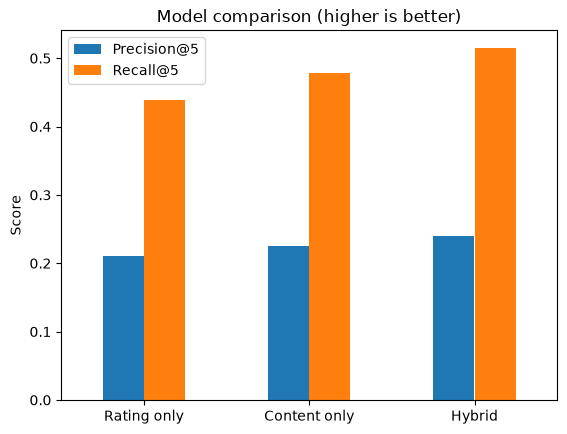

In [10]:
summary.plot(kind='bar', rot=0, title='Model comparison (higher is better)')
plt.ylabel('Score'); plt.show()

,alpha,Precision@5
0,0.0,0.211
1,0.2,0.215
2,0.4,0.233
3,0.6,0.240
4,0.8,0.232
5,1.0,0.225


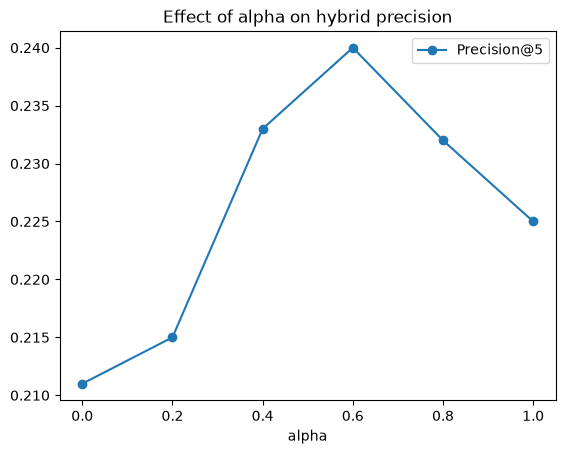

In [11]:
# Tune alpha for the hybrid model
rows = []
for a in [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]:
    p = []
    for uid in test.user_id.unique():
        relevant = set(test[(test.user_id==uid)&(test.rating>=4)].place_id)
        if not relevant: continue
        recs = rec_lists(uid, alpha=a)[2]
        p.append(len(relevant & set(recs))/K)
    rows.append((a, np.mean(p)))
alpha_df = pd.DataFrame(rows, columns=['alpha','Precision@5']).round(3)
display(alpha_df)
alpha_df.plot(x='alpha', y='Precision@5', marker='o', title='Effect of alpha on hybrid precision'); plt.show()

## Step 6: Interactive example (new tourist)
Change the interests, district or season below and re-run.

In [12]:
my_interests = 'photography culture heritage family'
recommend_hybrid(my_interests, n=5, alpha=0.6)

,place_id,name,district,category,best_season,content,rating,final_score
11,P012,Khaplu Palace (Khaplu Fort),Ghanche,Fort / Heritage,Apr-Oct,1.000,0.894,0.957
9,P010,Shigar Fort (Fong Khar),Shigar,Fort / Heritage,Apr-Oct,0.989,0.743,0.891
13,P014,Khaplu Valley,Ghanche,Valley,Apr-Oct,0.534,0.825,0.650
12,P013,Chaqchan Mosque,Ghanche,Religious / Heritage,Apr-Oct,0.741,0.510,0.649
21,P022,Buddha Rock (Manthal),Skardu,Buddhist Heritage,Apr-Oct,0.840,0.073,0.533


## Conclusion (write in your own words)
- Rating filtering gives popular, well-rated places but is the same for every tourist.
- Content-based filtering personalizes by interest but ignores quality.
- The hybrid model combines both; see the evaluation table and the alpha chart above to decide the best alpha.
- **Note:** ratings in this dataset are simulated. Results on real survey data may differ. Replace `baltistan_ratings_SYNTHETIC.csv` with real ratings and re-run all cells.

## Save Models & Pipeline Artifacts
Serialize the trained TF-IDF vectorizer, place feature matrix, precomputed similarity, weighted ratings, and processed metadata using `joblib` for deployment in the Flask web application.

In [ ]:
import os
import joblib
import json

os.makedirs('models', exist_ok=True)

# Save TF-IDF Vectorizer and Matrix
joblib.dump(tfidf, 'models/tfidf_vectorizer.joblib')
joblib.dump(X, 'models/tfidf_matrix.joblib')

# Save places processed dataframe & similarity matrix
joblib.dump(places, 'models/places_processed.joblib')
joblib.dump(cosine_similarity(X, X), 'models/place_similarity_matrix.joblib')

# Save rating statistics
rating_artifacts = {
    'C_global_mean': float(C_mean),
    'm_threshold': float(m),
    'place_stats': stats.set_index('place_id').to_dict(orient='index')
}
joblib.dump(rating_artifacts, 'models/rating_model.joblib')

print('All models and artifacts saved successfully into models/ directory!')
